In [4]:
from catboost import Pool, CatBoostRegressor, cv
from sklearn.model_selection import cross_validate
from sklearn.metrics import mean_absolute_percentage_error
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.7/98.7 MB 7.2 MB/s eta 0:00:00


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
def inform_data(data):
    print('_________________________________________________________________________________________________________________')
    print(data.info())
    print('_________________________________________________________________________________________________________________')
    print(data.head())
    print('_________________________________________________________________________________________________________________')
    print(data.isnull().sum())
    print('_________________________________________________________________________________________________________________')
    print(data.describe())
    print('_________________________________________________________________________________________________________________')

In [6]:
data = pd.read_csv('/content/drive/MyDrive/casco_train.csv')
data_test = pd.read_csv('/content/drive/MyDrive/casco_test.csv')
inform_data(data)

_________________________________________________________________________________________________________________
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24511 entries, 0 to 24510
Data columns (total 19 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   column_1   24511 non-null  int64  
 1   column_2   24425 non-null  float64
 2   column_3   24511 non-null  object 
 3   column_4   24511 non-null  object 
 4   column_5   24511 non-null  object 
 5   column_6   24511 non-null  float64
 6   column_7   24511 non-null  object 
 7   column_8   24511 non-null  float64
 8   column_9   24511 non-null  int64  
 9   column_10  24511 non-null  float64
 10  column_11  24511 non-null  int64  
 11  column_12  24511 non-null  int64  
 12  column_13  24511 non-null  float64
 13  column_14  24511 non-null  int64  
 14  column_15  24511 non-null  object 
 15  column_16  24511 non-null  int64  
 16  column_17  24511 non-null  object 
 17  column_18  2

In [7]:
data = data.drop(['column_18', 'column_14'], axis = 1)
data_test = data_test.drop(['column_18', 'column_14'], axis = 1)

In [8]:
data.loc[:, ['column_2', 'column_6', 'column_8', 'column_10', 'column_11', 'column_12','target']] = np.log1p(data.loc[:, ['column_2', 'column_6', 'column_8', 'column_10', 'column_11', 'column_12','target']])
data_test.loc[:, ['column_2', 'column_6', 'column_8', 'column_10', 'column_11', 'column_12']] = np.log1p(data_test.loc[:, ['column_2', 'column_6', 'column_8', 'column_10', 'column_11', 'column_12']])
data.head()


,column_1,column_2,column_3,column_4,column_5,column_6,column_7,column_8,column_9,column_10,column_11,column_12,column_13,column_15,column_16,column_17,target
0,2,2.776655,a1,b0,b0,3.988984,q2,0.693147,2,5.521461,3.178054,0.693147,58.025786,c4,1,k,14.948617
1,1,2.580285,a3,b0,b0,1.945910,q1,7.650169,4,4.820282,1.609438,1.386294,81.549097,c0,0,a,12.835366
2,2,3.938414,a1,b4,b4,2.411938,q1,0.693147,2,5.204007,2.302585,0.000000,76.689904,c3,1,j,13.806483
3,1,3.078764,a1,b86,b0,0.000000,q2,11.002117,7,5.356586,3.401197,0.000000,79.125201,c4,0,f,13.752556
4,2,3.963257,a1,b0,b0,3.637586,q1,10.780330,7,5.347108,2.995732,0.000000,81.549097,c1,0,h,13.562048


In [9]:
data.loc[:, ['column_4']] = (data.loc[:, ['column_4']] == 'b0').astype(int)
data_test.loc[:, ['column_4']] = (data_test.loc[:, ['column_4']] == 'b0').astype(int)
data.head()

,column_1,column_2,column_3,column_4,column_5,column_6,column_7,column_8,column_9,column_10,column_11,column_12,column_13,column_15,column_16,column_17,target
0,2,2.776655,a1,1,b0,3.988984,q2,0.693147,2,5.521461,3.178054,0.693147,58.025786,c4,1,k,14.948617
1,1,2.580285,a3,1,b0,1.945910,q1,7.650169,4,4.820282,1.609438,1.386294,81.549097,c0,0,a,12.835366
2,2,3.938414,a1,0,b4,2.411938,q1,0.693147,2,5.204007,2.302585,0.000000,76.689904,c3,1,j,13.806483
3,1,3.078764,a1,0,b0,0.000000,q2,11.002117,7,5.356586,3.401197,0.000000,79.125201,c4,0,f,13.752556
4,2,3.963257,a1,1,b0,3.637586,q1,10.780330,7,5.347108,2.995732,0.000000,81.549097,c1,0,h,13.562048


In [10]:
data.loc[:, ['column_5']] = (data.loc[:, ['column_5']] == 'b0').astype(int)
data_test.loc[:, ['column_5']] = (data_test.loc[:, ['column_5']] == 'b0').astype(int)
data.head()

,column_1,column_2,column_3,column_4,column_5,column_6,column_7,column_8,column_9,column_10,column_11,column_12,column_13,column_15,column_16,column_17,target
0,2,2.776655,a1,1,1,3.988984,q2,0.693147,2,5.521461,3.178054,0.693147,58.025786,c4,1,k,14.948617
1,1,2.580285,a3,1,1,1.945910,q1,7.650169,4,4.820282,1.609438,1.386294,81.549097,c0,0,a,12.835366
2,2,3.938414,a1,0,0,2.411938,q1,0.693147,2,5.204007,2.302585,0.000000,76.689904,c3,1,j,13.806483
3,1,3.078764,a1,0,1,0.000000,q2,11.002117,7,5.356586,3.401197,0.000000,79.125201,c4,0,f,13.752556
4,2,3.963257,a1,1,1,3.637586,q1,10.780330,7,5.347108,2.995732,0.000000,81.549097,c1,0,h,13.562048


In [11]:
data.loc[:, ['column_7']] = (data.loc[:, ['column_7']] == 'q1').astype(int)
data_test.loc[:, ['column_7']] = (data_test.loc[:, ['column_7']] == 'q1').astype(int)
data.head()

,column_1,column_2,column_3,column_4,column_5,column_6,column_7,column_8,column_9,column_10,column_11,column_12,column_13,column_15,column_16,column_17,target
0,2,2.776655,a1,1,1,3.988984,0,0.693147,2,5.521461,3.178054,0.693147,58.025786,c4,1,k,14.948617
1,1,2.580285,a3,1,1,1.945910,1,7.650169,4,4.820282,1.609438,1.386294,81.549097,c0,0,a,12.835366
2,2,3.938414,a1,0,0,2.411938,1,0.693147,2,5.204007,2.302585,0.000000,76.689904,c3,1,j,13.806483
3,1,3.078764,a1,0,1,0.000000,0,11.002117,7,5.356586,3.401197,0.000000,79.125201,c4,0,f,13.752556
4,2,3.963257,a1,1,1,3.637586,1,10.780330,7,5.347108,2.995732,0.000000,81.549097,c1,0,h,13.562048


2


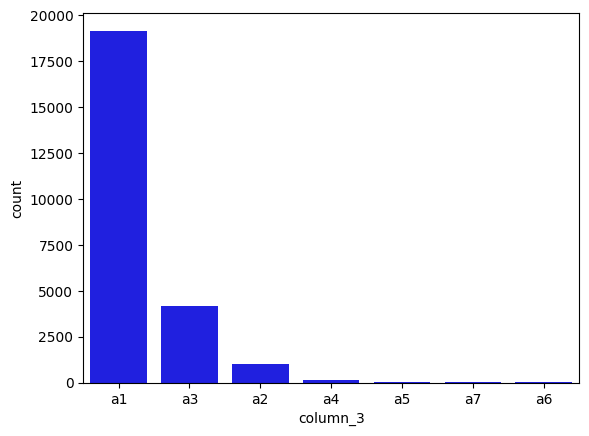

3


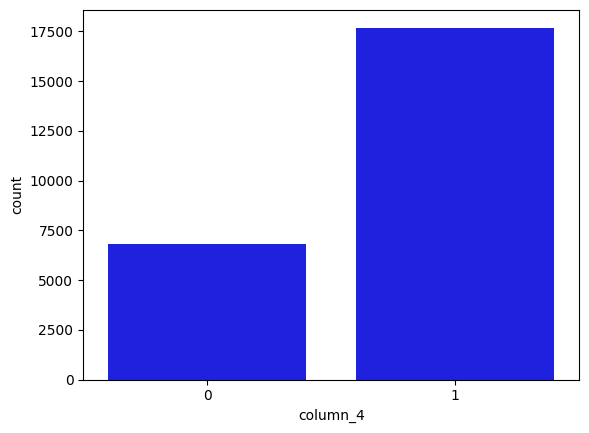

4


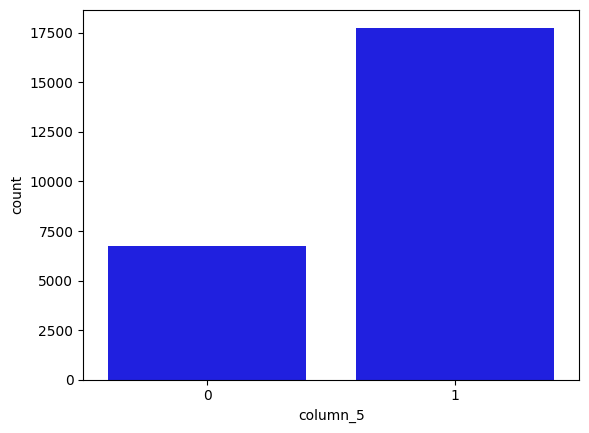

6


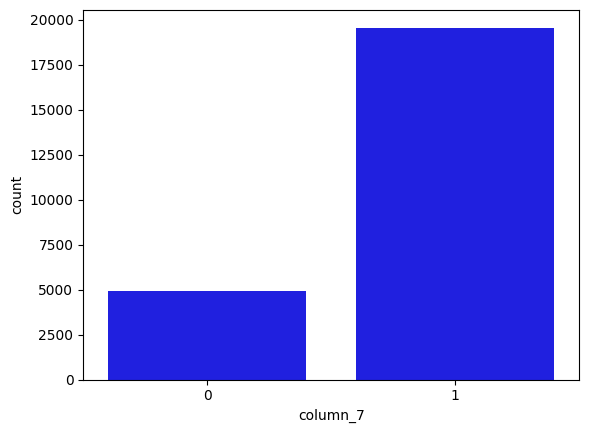

13


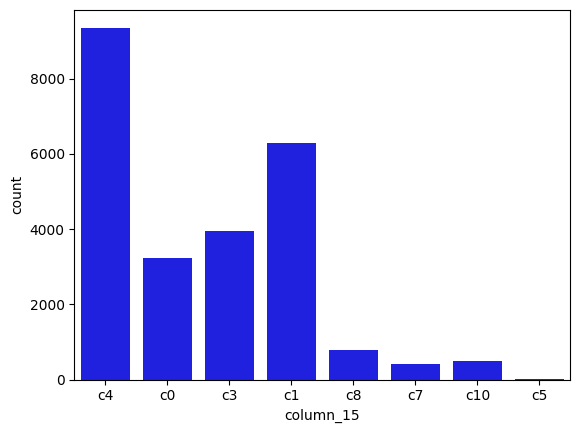

15


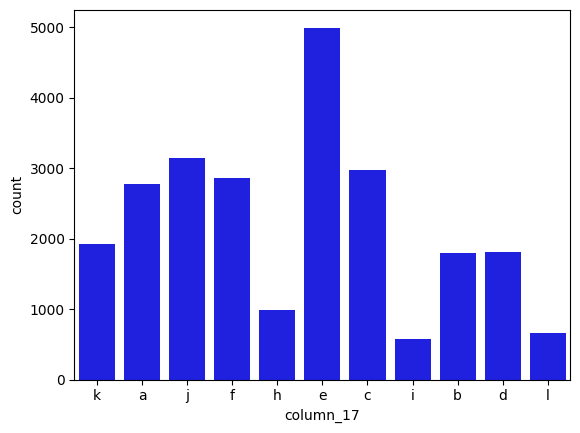

In [12]:
%matplotlib inline
def plot_colomns(data):
    cat_features = []
    for i in range(data.shape[1]):
        if (data.iloc[:, i].dtype == 'object') or (i == 3) or (i == 4) or (i == 6):
            cat_features.append(data.columns[i])
            print(i)
            sns.countplot(x=data.columns[i], data = data, color ='b')
            plt.show()
    return cat_features



cat_features = plot_colomns(data)

In [13]:
y = data.target
x = data.drop('target', axis = 1)
x

,column_1,column_2,column_3,column_4,column_5,column_6,column_7,column_8,column_9,column_10,column_11,column_12,column_13,column_15,column_16,column_17
0,2,2.776655,a1,1,1,3.988984,0,0.693147,2,5.521461,3.178054,0.693147,58.025786,c4,1,k
1,1,2.580285,a3,1,1,1.945910,1,7.650169,4,4.820282,1.609438,1.386294,81.549097,c0,0,a
2,2,3.938414,a1,0,0,2.411938,1,0.693147,2,5.204007,2.302585,0.000000,76.689904,c3,1,j
3,1,3.078764,a1,0,1,0.000000,0,11.002117,7,5.356586,3.401197,0.000000,79.125201,c4,0,f
4,2,3.963257,a1,1,1,3.637586,1,10.780330,7,5.347108,2.995732,0.000000,81.549097,c1,0,h
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24506,1,3.307080,a1,1,1,3.850148,1,10.628642,7,4.955827,2.890372,1.386294,65.580824,c3,0,d
24507,2,3.255037,a1,1,1,1.609438,1,10.090009,4,5.416100,2.890372,1.098612,76.689904,c4,0,f
24508,2,2.939670,a3,1,1,0.000000,1,9.998843,5,4.955827,1.945910,1.098612,54.199037,c3,0,d
24509,2,3.078764,a1,0,0,3.951244,1,11.034712,9,5.641907,2.995732,0.000000,55.478435,c1,0,j


In [16]:
cv_dataset = Pool(data = x,
                  label = y,
                  cat_features = cat_features)

params = {"iterations": 340,
          "depth": 7,
          "loss_function": "MAPE",
          "verbose": False}

#scores = cv(cv_dataset,             params,             fold_count=5,            plot="True")

grid = {"iterations": [340],
        "depth": [3, 5, 7, 9, 11],
        "l2_leaf_reg": [1, 3, 5, 7, 9]}
model = CatBoostRegressor(loss_function = "MAPE", verbose = False)
grid_search_result = model.grid_search(grid,
                                       cv_dataset,
                                       plot=True)

MetricVisualizer(layout=Layout(align_self='stretch', height='500px'))


bestTest = 0.009507349624
bestIteration = 339

0:	loss: 0.0095073	best: 0.0095073 (0)	total: 3.18s	remaining: 1m 16s

bestTest = 0.009533031833
bestIteration = 339

1:	loss: 0.0095330	best: 0.0095073 (0)	total: 8.01s	remaining: 1m 32s

bestTest = 0.009547068497
bestIteration = 339

2:	loss: 0.0095471	best: 0.0095073 (0)	total: 11.4s	remaining: 1m 23s

bestTest = 0.009557148108
bestIteration = 339

3:	loss: 0.0095571	best: 0.0095073 (0)	total: 14.5s	remaining: 1m 16s

bestTest = 0.009592522154
bestIteration = 339

4:	loss: 0.0095925	best: 0.0095073 (0)	total: 17.6s	remaining: 1m 10s

bestTest = 0.008541396461
bestIteration = 339

5:	loss: 0.0085414	best: 0.0085414 (5)	total: 24.7s	remaining: 1m 18s

bestTest = 0.008430490457
bestIteration = 339

6:	loss: 0.0084305	best: 0.0084305 (6)	total: 29.9s	remaining: 1m 16s

bestTest = 0.008492256196
bestIteration = 339

7:	loss: 0.0084923	best: 0.0084305 (6)	total: 36.3s	remaining: 1m 17s

bestTest = 0.008457730025
bestIteration = 339

8:	loss:

In [17]:
test_pool = Pool(data = data_test, cat_features = cat_features)

# specify the training parameters
model = CatBoostRegressor(iterations = 340, depth = 11, loss_function = "MAPE", verbose = False)
#train the model
model.fit(cv_dataset)
# make the prediction using the resulting model
preds = model.predict(test_pool)


In [23]:
model

In [18]:
y_pred = np.expm1(preds)
print(y_pred[:5])

[ 680554.42818703  970129.04559312  737856.89907599 1139524.72019407
  609458.82840131]


In [19]:
data_test.head()

,id,column_1,column_2,column_3,column_4,column_5,column_6,column_7,column_8,column_9,column_10,column_11,column_12,column_13,column_15,column_16,column_17
0,1,1,3.606647,a1,1,1,2.079442,1,9.741086,6,5.220356,3.465736,1.945910,74.242880,c4,0,k
1,2,2,4.099230,a1,1,1,0.000000,1,10.896758,5,5.347108,3.218876,0.000000,86.363908,c8,0,h
2,3,2,3.255037,a1,1,1,3.610918,1,10.781536,8,5.349201,1.609438,0.000000,69.312262,c8,0,h
3,4,1,2.464962,a3,1,1,3.637586,1,10.463132,7,5.505332,2.639057,1.791759,56.753996,c4,1,k
4,5,2,3.199900,a1,0,0,1.098612,1,10.430374,6,5.141664,1.386294,0.693147,71.783787,c1,0,e


In [20]:
result = pd.DataFrame(data_test.id)
result['target'] = y_pred
result.to_csv('result.csv', index = False)

In [22]:
result

,id,target
0,1,6.805544e+05
1,2,9.701290e+05
2,3,7.378569e+05
3,4,1.139525e+06
4,5,6.094588e+05
...,...,...
3657,3658,4.377330e+05
3658,3659,6.713672e+05
3659,3660,3.496827e+05
3660,3661,3.458232e+05


In [21]:
from google.colab import files

# Выкачивание файла
files.download('result.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>